# EDA: Default of Credit Card Clients

Разведочный анализ перед обучением PD-модели. Смотрю качество данных, баланс классов,
связь признаков с дефолтом и проверяю новые признаки из `src/features/build_features.py`.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data.columns import RAW_TARGET, BILL_COLS, PAY_AMT_COLS
from src.data.make_dataset import clean_data
from src.features.build_features import add_features, NEW_NUMERIC_FEATURES

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/raw/UCI_Credit_Card.csv")
df.shape

(30000, 25)

## 1. Качество данных

In [2]:
print("Пропусков всего:", df.isnull().sum().sum())
print("ID уникален:", df["ID"].is_unique)
print("Полных дублей без учёта ID:", df.drop(columns="ID").duplicated().sum())
print(df.dtypes.value_counts())

Пропусков всего: 0
ID уникален: True
Полных дублей без учёта ID: 35
float64    13
int64      12
Name: count, dtype: int64


In [3]:
df.describe().T[["mean", "min", "50%", "max"]].round(1)

,mean,min,50%,max
ID,15000.5,1.0,15000.5,30000.0
LIMIT_BAL,167484.3,10000.0,140000.0,1000000.0
SEX,1.6,1.0,2.0,2.0
EDUCATION,1.9,0.0,2.0,6.0
MARRIAGE,1.6,0.0,2.0,3.0
AGE,35.5,21.0,34.0,79.0
PAY_0,-0.0,-2.0,0.0,8.0
PAY_2,-0.1,-2.0,0.0,8.0
PAY_3,-0.2,-2.0,0.0,8.0
PAY_4,-0.2,-2.0,0.0,8.0


In [4]:
# отрицательный счёт - это переплата клиента, а не ошибка
(df[BILL_COLS] < 0).sum()

BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64

Пропусков нет, `ID` уникален, 35 полных дублей (удаляю при очистке).
Отрицательные значения в `BILL_AMT*` оставляю как есть.

## 2. Целевая переменная

default.payment.next.month
0    0.779
1    0.221
Name: доля, dtype: float64


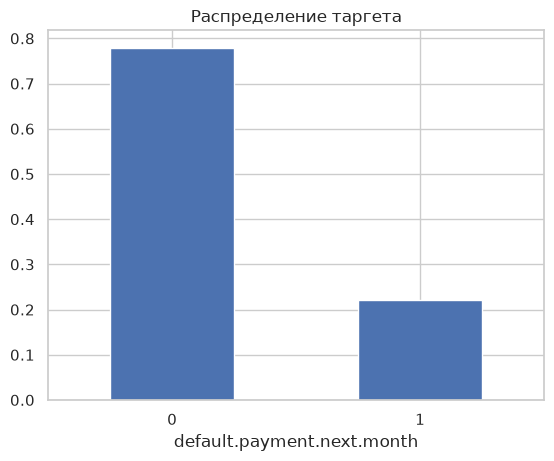

In [5]:
target_share = df[RAW_TARGET].value_counts(normalize=True).rename("доля")
print(target_share.round(3))

target_share.plot(kind="bar", title="Распределение таргета", rot=0)
plt.show()

Дефолтов около 22%, классы несбалансированы. Поэтому разбиение делаю со стратификацией,
основная метрика ROC-AUC, accuracy не показательна.

## 3. Категориальные признаки

In [6]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    stat = df.groupby(col)[RAW_TARGET].agg(["count", "mean"]).rename(
        columns={"count": "клиентов", "mean": "доля дефолтов"}
    )
    print(stat.round(3), end="\n\n")

     клиентов  доля дефолтов
SEX                         
1       11888          0.242
2       18112          0.208

           клиентов  доля дефолтов
EDUCATION                         
0                14          0.000
1             10585          0.192
2             14030          0.237
3              4917          0.252
4               123          0.057
5               280          0.064
6                51          0.157

          клиентов  доля дефолтов
MARRIAGE                         
0               54          0.093
1            13659          0.235
2            15964          0.209
3              323          0.260



В `EDUCATION` есть коды 0, 5, 6, а в `MARRIAGE` код 0, которых нет в описании датасета.
Их мало, при очистке объединяю с категорией «прочее» (4 и 3 соответственно).

## 4. История платежей

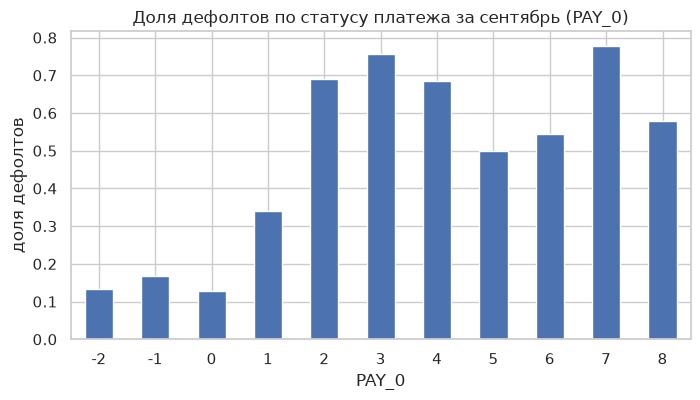

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
df.groupby("PAY_0")[RAW_TARGET].mean().plot(kind="bar", ax=ax, rot=0)
ax.set_title("Доля дефолтов по статусу платежа за сентябрь (PAY_0)")
ax.set_ylabel("доля дефолтов")
plt.show()

Самый сильный признак. При `PAY_0 >= 2` (просрочка от двух месяцев) доля дефолтов
0.6-0.7, у тех, кто платит вовремя, около 0.13.

## 5. Числовые признаки

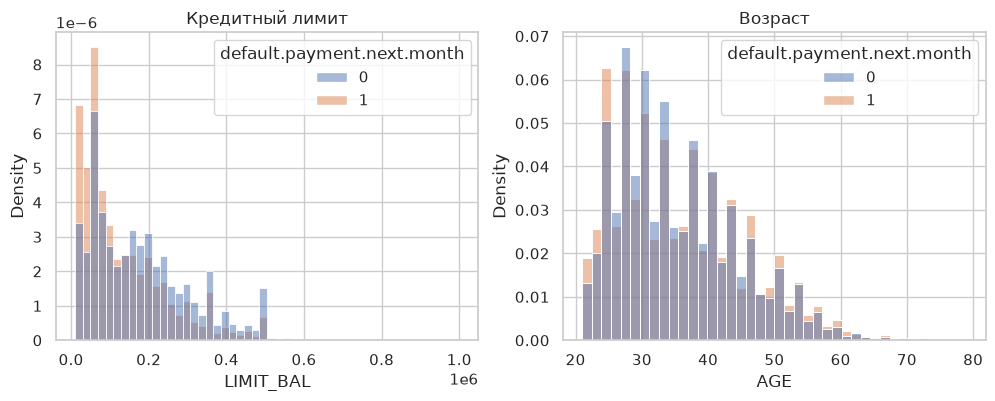

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="LIMIT_BAL", hue=RAW_TARGET, bins=50, stat="density",
             common_norm=False, ax=axes[0])
sns.histplot(data=df, x="AGE", hue=RAW_TARGET, bins=40, stat="density",
             common_norm=False, ax=axes[1])
axes[0].set_title("Кредитный лимит")
axes[1].set_title("Возраст")
plt.show()

In [9]:
corr = df.drop(columns="ID").corr(method="spearman")[RAW_TARGET].drop(RAW_TARGET)
corr.sort_values(key=abs, ascending=False).round(3).head(12)

PAY_0        0.292
PAY_2        0.217
PAY_3        0.195
PAY_4        0.174
LIMIT_BAL   -0.170
PAY_AMT1    -0.160
PAY_5        0.159
PAY_AMT2    -0.151
PAY_6        0.143
PAY_AMT3    -0.139
PAY_AMT4    -0.128
PAY_AMT6    -0.121
Name: default.payment.next.month, dtype: float64

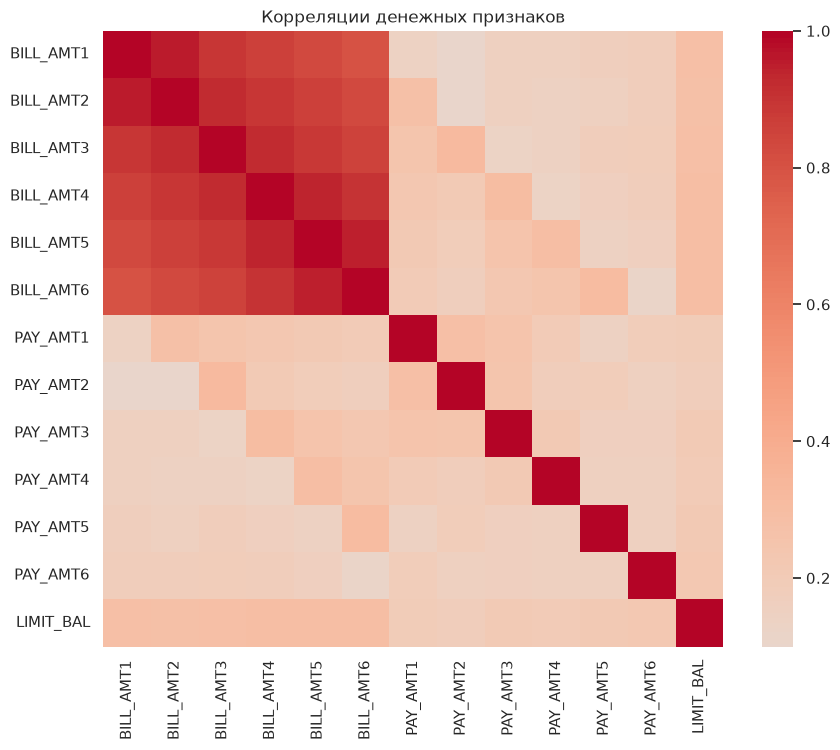

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[BILL_COLS + PAY_AMT_COLS + ["LIMIT_BAL"]].corr(), cmap="coolwarm", center=0)
plt.title("Корреляции денежных признаков")
plt.show()

У клиентов с дефолтом лимит в среднем ниже. Возраст влияет слабо и нелинейно,
поэтому для него делаю биннинг. `BILL_AMT1..6` сильно коррелируют между собой
(мультиколлинеарность), это аргумент в пользу агрегатов и регуляризации в LogReg.

## 6. Новые признаки

In [11]:
fe = add_features(clean_data(df))
fe[NEW_NUMERIC_FEATURES + ["target"]].corr(method="spearman")["target"].drop("target").round(3)

MONTHS_DELAYED    0.388
MAX_DELAY         0.373
UTILIZATION       0.073
BILL_MEAN        -0.027
PAY_AMT_MEAN     -0.175
PAY_RATIO        -0.113
Name: target, dtype: float64

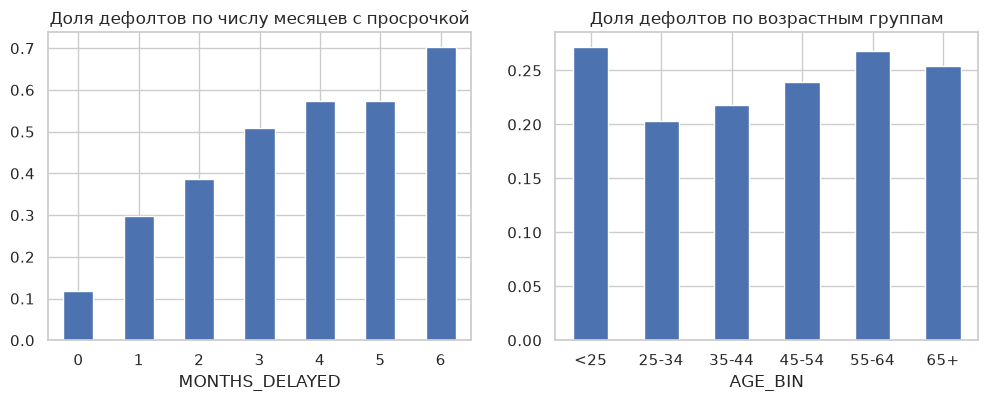

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fe.groupby("MONTHS_DELAYED")["target"].mean().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Доля дефолтов по числу месяцев с просрочкой")
order = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
fe.groupby("AGE_BIN")["target"].mean().reindex(order).plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Доля дефолтов по возрастным группам")
plt.show()

## Выводы

- Данные чистые: пропусков нет, есть 35 дублей и несколько недокументированных кодов,
  которые обрабатываются в `src/data/make_dataset.py`.
- Классы несбалансированы (22% дефолтов): стратификация, ROC-AUC, подбор порога.
- Главные признаки связаны с историей просрочек (`PAY_*`), новые признаки
  `MONTHS_DELAYED` и `MAX_DELAY` их хорошо агрегируют.
- Возраст влияет нелинейно (риск выше у самых молодых и у старших групп),
  поэтому добавлен `AGE_BIN`.